# Construction Safety AI

Train a YOLO detector on construction-site objects and PPE, then annotate a photo or video. The source dataset has boxes, not masks, so this model draws **object-detection boxes**. A separately trained segmentation model can add masks.

The demo flags explicit `no-hardhat`, `no-mask`, and `no-safety vest` detections for human review. It does not prove a safety-code violation.

In [1]:
%pip install -q ultralytics datasets huggingface_hub opencv-python-headless pyyaml pillow

In [2]:
from collections import Counter
from pathlib import Path
import json
import os
import shutil
import subprocess

import cv2
import yaml
from ultralytics import YOLO

DATA_DIR = Path("construction_safety_yolo").resolve()
RUN_DIR = Path("runs/construction_safety").resolve()
OUTPUT_DIR = Path("outputs").resolve()
OUTPUT_DIR.mkdir(exist_ok=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 1. Prepare data

The [source dataset](https://huggingface.co/datasets/pyimagesearch/construction-safety-object-detection-paligemma) may require accepting access terms. Set `HF_TOKEN` in your environment or Colab Secrets. For a different YOLO dataset, set `EXISTING_YOLO_YAML` to its configuration file. Never paste a token into this notebook.

In [6]:
EXISTING_YOLO_YAML = None  # Example: "/content/my_dataset/data.yaml"

if EXISTING_YOLO_YAML:
    data_yaml = Path(EXISTING_YOLO_YAML).resolve()
else:
    from datasets import load_dataset
    from google.colab import userdata
    from huggingface_hub import login

    # Retrieve the HF_TOKEN secret and authenticate
    try:
        hf_token = userdata.get("HF_TOKEN")
        login(token=hf_token)
    except Exception as e:
        print("Warning: Could not fetch HF_TOKEN from Colab Secrets. Ensure 'HF_TOKEN' is added in the Secrets tab.")
        hf_token = os.environ.get("HF_TOKEN")

    dataset = load_dataset(
        "pyimagesearch/construction-safety-object-detection-paligemma",
        token=hf_token,
    )

    # Safely fetch class names avoiding nested Sequence AttributeErrors
    objects_feature = dataset["train"].features["objects"]
    if hasattr(objects_feature, "feature") and "category" in objects_feature.feature:
        class_names = objects_feature.feature["category"].names
    else:
        class_names = dataset["train"].features["objects"]["category"].feature.names

    for source_split, yolo_split in [("train", "train"), ("validation", "val"), ("test", "test")]:
        images = DATA_DIR / "images" / yolo_split
        labels = DATA_DIR / "labels" / yolo_split
        images.mkdir(parents=True, exist_ok=True)
        labels.mkdir(parents=True, exist_ok=True)

        for index, sample in enumerate(dataset[source_split]):
            image = sample["image"].convert("RGB")
            width, height = image.size
            image.save(images / f"{index:05d}.jpg")

            rows = []
            for (x, y, box_width, box_height), category in zip(
                sample["objects"]["bbox"], sample["objects"]["category"]
            ):
                center_x = (x + box_width / 2) / width
                center_y = (y + box_height / 2) / height
                rows.append(f"{category} {center_x:.6f} {center_y:.6f} "
                            f"{box_width / width:.6f} {box_height / height:.6f}")
            (labels / f"{index:05d}.txt").write_text("\n".join(rows))

    data_yaml = DATA_DIR / "data.yaml"
    data_yaml.write_text(yaml.safe_dump({
        "path": str(DATA_DIR), "train": "images/train", "val": "images/val",
        "test": "images/test", "names": class_names,
    }, sort_keys=False))

print("Dataset configuration:", data_yaml)

Dataset configuration: /content/construction_safety_yolo/data.yaml


## 2. Train and evaluate

Use the trained `best.pt` for every later step. A generic COCO model does not know this dataset's PPE classes. Adjust epochs and batch for your hardware.

In [7]:
model = YOLO("yolo11n.pt")
model.train(data=str(data_yaml), epochs=40, imgsz=640, batch=8,
            project=str(RUN_DIR), name="detector", exist_ok=True)

weights = RUN_DIR / "detector" / "weights" / "best.pt"
model = YOLO(str(weights))

config = yaml.safe_load(data_yaml.read_text())
split = "test" if config.get("test") else "val"
metrics = model.val(data=str(data_yaml), split=split)
print(f"{split} mAP50: {metrics.box.map50:.3f}")
print(f"{split} mAP50-95: {metrics.box.map:.3f}")

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/construction_safety_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=detector, nbs=64, nms=None, opset=

## 3. Annotate an image or video

Set `INPUT_PATH` locally, or leave it as `None` to upload in Colab. The output is an annotated media file plus JSON. Video counts are observations across frames, not unique workers.

In [8]:
INPUT_PATH = None  # Example: "/content/construction_video.mp4"

if INPUT_PATH is None:
    from google.colab import files
    INPUT_PATH = next(iter(files.upload()))

source = Path(INPUT_PATH).resolve()
if source.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp", ".mp4", ".mov", ".avi", ".mkv"}:
    raise ValueError("Choose an image or video file")

def read_boxes(result):
    return [{
        "label": result.names[int(box.cls.item())],
        "confidence": round(float(box.conf.item()), 3),
        "box": [round(float(value), 1) for value in box.xyxy[0].tolist()],
    } for box in result.boxes]

all_labels = Counter()
concerns = Counter()
alert_classes = {"no-hardhat", "no-mask", "no-safety vest"}

def count_boxes(boxes):
    all_labels.update(box["label"] for box in boxes)
    concerns.update(box["label"] for box in boxes if box["label"].lower() in alert_classes)

if source.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}:
    result = model.predict(str(source), conf=0.30, verbose=False)[0]
    boxes = read_boxes(result)
    count_boxes(boxes)
    output = OUTPUT_DIR / f"{source.stem}_annotated.jpg"
    cv2.imwrite(str(output), result.plot())
    report = {"type": "image", "detections": boxes}
else:
    cap = cv2.VideoCapture(str(source))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    size = (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    raw_output = OUTPUT_DIR / f"{source.stem}_raw.mp4"
    writer = cv2.VideoWriter(str(raw_output), cv2.VideoWriter_fourcc(*"mp4v"), fps, size)
    events = []
    frame_number = 0

    while True:
        ok, frame = cap.read()
        if not ok:
            break
        result = model.predict(frame, conf=0.30, verbose=False)[0]
        boxes = read_boxes(result)
        count_boxes(boxes)
        flagged = [box for box in boxes if box["label"].lower() in alert_classes]
        if flagged:
            events.append({"time_s": round(frame_number / fps, 2), "detections": flagged})
        writer.write(result.plot())
        frame_number += 1

    cap.release()
    writer.release()
    output = OUTPUT_DIR / f"{source.stem}_annotated.mp4"
    if shutil.which("ffmpeg"):
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(raw_output),
                        "-c:v", "libx264", "-pix_fmt", "yuv420p", str(output)], check=True)
        raw_output.unlink()
    else:
        output = raw_output
    report = {"type": "video", "frames": frame_number, "fps": fps, "events": events}

report["class_counts"] = dict(all_labels)
report["possible_ppe_concerns"] = dict(concerns)
report["note"] = "Review all possible concerns manually. Video counts are frame observations."
report_path = OUTPUT_DIR / f"{source.stem}_report.json"
report_path.write_text(json.dumps(report, indent=2))
print("Annotated media:", output)
print("Report:", report_path)

Saving sample-construction.jpg to sample-construction.jpg
Annotated media: /content/outputs/sample-construction_annotated.jpg
Report: /content/outputs/sample-construction_report.json


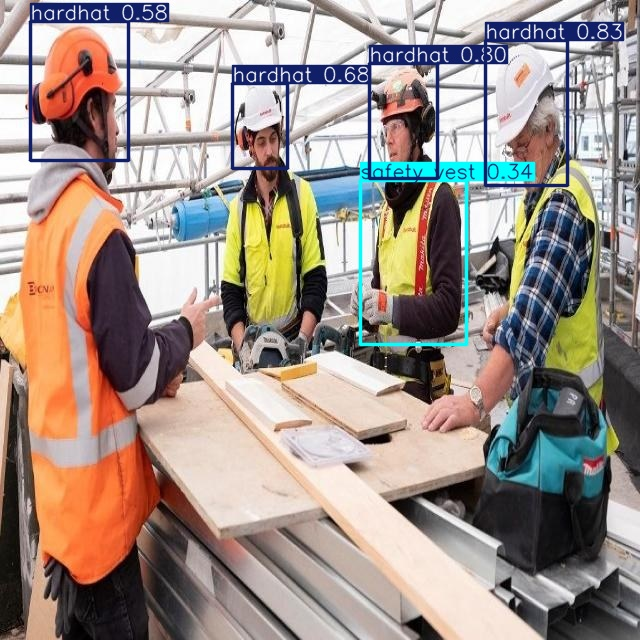

In [9]:
from IPython.display import Video, display
from PIL import Image

display(Image.open(output) if report["type"] == "image" else Video(str(output), embed=True))

## 4. Run the website

Copy `best.pt` into `app/models/best.pt`. The accompanying website uses that checkpoint to analyze uploaded files and its two sample scenes. The construction dataset has only box labels; masks require separately trained segmentation weights.